# Day 12 · Bag of Visual Words (BoVW): a texture classifier that actually works

**Course lab:** `CV-Week2-Lecture5.ipynb` (Day 12: Bag of Visual Words)
**Notes chapter:** `week-2/notes/05_bag_of_visual_words.md`
**Run time:** about 2–3 minutes on a laptop CPU (downloads about 12 MB of texture photos the first time).

**What you will learn**
- How to turn an image with *any number* of SIFT descriptors into **one fixed-length vector** (a histogram of "visual words").
- What k-means clustering does and what a "visual word" looks like.
- How vocabulary size `k` affects accuracy, and why histograms must be normalised.
- How to train and evaluate an SVM on BoVW histograms **properly** (train/test split, confusion matrix, an "unseen photo" test).
- Why the course notebook could never work (3 images, 1 per class) and how to fix it.

## 1 · The idea in plain language

BoVW borrows a trick from text classification. To decide whether an email is spam you can ignore word order and just **count words**: lots of "winner", "free", "prize" → spam. An image can be treated the same way:

| Text | Image |
|---|---|
| document | image (here: a texture patch) |
| word | **visual word** = a typical small-patch pattern (a corner of a brick, a blade of grass…) |
| dictionary | **vocabulary** = the k cluster centres found by k-means |
| word-count histogram | **BoVW histogram**: how often each visual word appears in the image |
| spam classifier | SVM trained on the histograms |

**The pipeline (learn this order for the viva):**
1. **Extract local features**: SIFT finds keypoints and describes the patch around each one with a **128-number descriptor** (gradient-direction histograms: 4×4 cells × 8 directions).
2. **Build the vocabulary**: run **k-means** on all *training* descriptors. Each of the k cluster centres is a visual word. (Analogy from the Key Concepts: grouping synonyms. Many slightly different "brick corner" descriptors all fall into one cluster.)
3. **Encode each image**: assign every descriptor to its nearest visual word and count → a histogram of length k. Divide by the total so it sums to 1.
4. **Classify**: feed the histograms to an SVM (or kNN).

**Why bother?** One image may have 40 descriptors and another 300. Classifiers like SVM need **the same number of features for every image**. The histogram always has exactly k numbers, whatever the number of keypoints.

**What BoVW throws away:** *where* the features are (it is a "bag"; order and position are lost). That is fine for textures (a brick wall is "brick-like" everywhere) and a weakness for objects whose layout matters.

## 2 · Setup and a small download helper
Install once: `pip install opencv-python scikit-learn scikit-image matplotlib`. SIFT is in the main `opencv-python` package since OpenCV 4.4 (the patent expired in 2020).

In [1]:
%matplotlib inline
import time
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from threadpoolctl import threadpool_limits

threadpool_limits(2)              # optional: use at most 2 CPU cores
cv2.setNumThreads(2)
plt.rcParams["figure.dpi"] = 80
print("OpenCV", cv2.__version__, "| SIFT available:", hasattr(cv2, "SIFT_create"))

DATA = Path("data/textures")
DATA.mkdir(parents=True, exist_ok=True)

def download(url, name=None):
    """Download url into data/textures/ once; later runs reuse the cached file."""
    path = DATA / (name or url.split("/")[-1])
    if not path.exists():
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            raise RuntimeError(f"Could not download {url}: {e}\nAre you offline? Download the file by hand into {DATA}/") from e
    return path

OpenCV 5.0.0 | SIFT available: True


## 3 · Why the course notebook cannot work

The course code loads **three images** (`'sample.jpg', 'left.jpg', 'right.jpg'`) and gives each one **its own class** (0, 1, 2). Then `train_test_split(..., test_size=0.3)` on 3 samples puts **2 images in training and 1 in testing**. The test image's class has *never been seen during training*, so the SVM **cannot** predict it: the course output shows 0% accuracy with "support 1.0". No setting of k or the kernel could fix this; it is a data problem, not a model problem.

Let's reproduce that failure with 3 texture photos (one per class), using the course's own code structure:

In [2]:
from skimage import data as skdata    # scikit-image ships a few real texture photos (brick, grass, gravel)

course_imgs = [skdata.brick(), skdata.grass(), skdata.gravel()]   # 3 images, 1 per class, as in the course
labels = [0, 1, 2]

sift = cv2.SIFT_create()
descriptors = []
for idx, img in enumerate(course_imgs):
    kp, des = sift.detectAndCompute(img, None)
    if des is not None:
        descriptors.extend(des)
descriptors = np.array(descriptors)
print("Collected descriptors shape:", descriptors.shape)

k = 20
kmeans = KMeans(n_clusters=k, random_state=42).fit(descriptors)
X = np.array([np.bincount(kmeans.predict(sift.detectAndCompute(im, None)[1]), minlength=k) for im in course_imgs])
y = np.array(labels)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("train labels:", y_train, " test label:", y_test)
svm = SVC(kernel='linear').fit(X_train, y_train)
print("prediction:", svm.predict(X_test), "-> accuracy", accuracy_score(y_test, svm.predict(X_test)))
print("Can the SVM ever output the test class?", y_test[0] in svm.classes_)

Collected descriptors shape: (12499, 128)


train labels: [1 2]  test label: [0]
prediction: [1] -> accuracy 0.0
Can the SVM ever output the test class? False


Exactly the course's failure: the test image is class 0 (brick), but the SVM only knows classes 1 and 2, so it is impossible to be right.

**The fix:** a real dataset with **many images per class**, split so that every class appears in both training and testing. Large texture photos make this easy: we cut **many patches** from each photo, and we make sure training and test patches come from **different regions** (and, in a harder test, from **different photos**).

(About the `RuntimeWarning: divide by zero / overflow encountered in matmul` lines in the course output: they come from the course author's machine (numpy on macOS with Apple's Accelerate maths library is known to print these spurious warnings inside scikit-learn's k-means), not from the method. They do not appear here.)

## 4 · Building a real texture dataset

Seven texture classes from freely downloadable texture photos: example textures shipped with the **three.js** and **Babylon.js** 3D libraries (photographs of real materials prepared for 3D graphics) and the three texture photos inside **scikit-image**. Where possible a class has **two or three different photos**.

We convert everything to **grayscale** (SIFT only uses brightness, so colour cannot help or "cheat") and shrink large photos so the short side is at most 512 pixels, keeping texture scale roughly comparable.

In [3]:
TJ = "https://raw.githubusercontent.com/mrdoob/three.js/dev/examples/textures/"
BJ = "https://raw.githubusercontent.com/BabylonJS/Assets/master/textures/"

sources = {   # class -> list of (name, url or 'skimage:<name>')
    "brick":  [("brick_A", TJ + "brick_diffuse.jpg"), ("brick_B", "skimage:brick")],
    "grass":  [("grass_A", BJ + "grass.png"), ("grass_B", TJ + "terrain/grasslight-big.jpg"), ("grass_C", "skimage:grass")],
    "gravel": [("gravel_A", "skimage:gravel"), ("gravel_B", BJ + "sand.jpg"), ("gravel_C", BJ + "ground.jpg")],
    "wood":   [("wood_A", TJ + "hardwood2_diffuse.jpg"), ("wood_B", BJ + "wood.jpg"), ("wood_C", BJ + "crate.png")],
    "ice":    [("ice_A", TJ + "ambientcg/Ice002_1K-JPG_Color.jpg"), ("ice_B", TJ + "ambientcg/Ice003_1K-JPG_Color.jpg")],
    "paving": [("paving_A", BJ + "floor.png")],
    "fur":    [("fur_A", BJ + "fur.jpg")],
}
class_names = list(sources)

def load_gray(src, name):
    if src.startswith("skimage:"):
        img = getattr(skdata, src.split(":")[1])()
    else:
        img = cv2.imread(str(download(src, name + Path(src).suffix)), cv2.IMREAD_GRAYSCALE)
    if name == "wood_C":
        img = img[40:216, 40:216]          # crate texture: keep only the planks, cut off the frame
    s = 512 / min(img.shape)
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img

photos = {c: [(n, load_gray(u, n)) for n, u in lst] for c, lst in sources.items()}
for c in class_names:
    print(f"{c:7s}", [(n, im.shape) for n, im in photos[c]])

brick   [('brick_A', (512, 512)), ('brick_B', (512, 512))]
grass   [('grass_A', (512, 512)), ('grass_B', (512, 512)), ('grass_C', (512, 512))]
gravel  [('gravel_A', (512, 512)), ('gravel_B', (512, 512)), ('gravel_C', (512, 512))]
wood    [('wood_A', (512, 1024)), ('wood_B', (256, 256)), ('wood_C', (176, 176))]
ice     [('ice_A', (512, 512)), ('ice_B', (512, 512))]
paving  [('paving_A', (512, 512))]
fur     [('fur_A', (512, 512))]


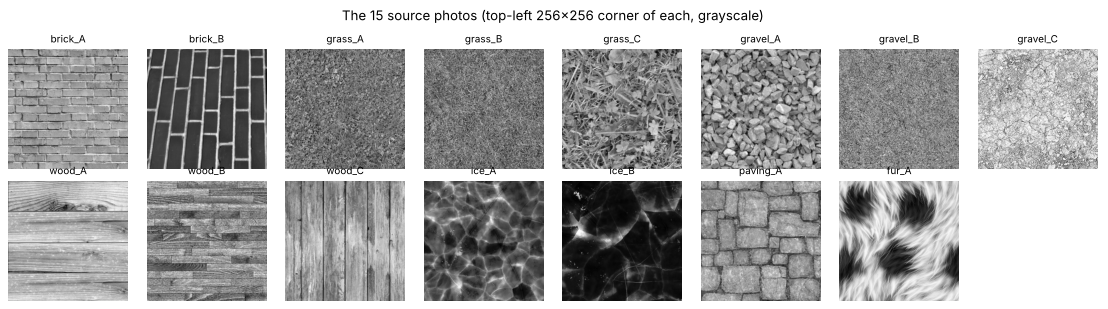

In [4]:
allp = [(c, n, im) for c in class_names for n, im in photos[c]]
fig, axes = plt.subplots(2, 8, figsize=(14, 3.9))
for a in axes.ravel(): a.axis("off")
for a, (c, n, im) in zip(axes.ravel(), allp):
    a.imshow(im[:256, :256], cmap="gray"); a.set_title(n, fontsize=9)
plt.suptitle("The 15 source photos (top-left 256x256 corner of each, grayscale)"); plt.tight_layout(); plt.show()

### Cutting patches, with a clean train/test split

Each photo is split **vertically**: patches from the **left 60%** go to training, patches from the **right 40%** go to testing. Patches are 128×128 and step 64 pixels, so neighbouring training patches overlap, but **no test patch shares a single pixel with a training patch**. (If we just shuffled overlapping patches into train/test, near-copies would end up on both sides and the accuracy would be inflated.)

training patches: 311, test patches: 203
per class (train / test): {'brick': (42, 28), 'grass': (63, 42), 'gravel': (63, 42), 'wood': (59, 35), 'ice': (42, 28), 'paving': (21, 14), 'fur': (21, 14)}


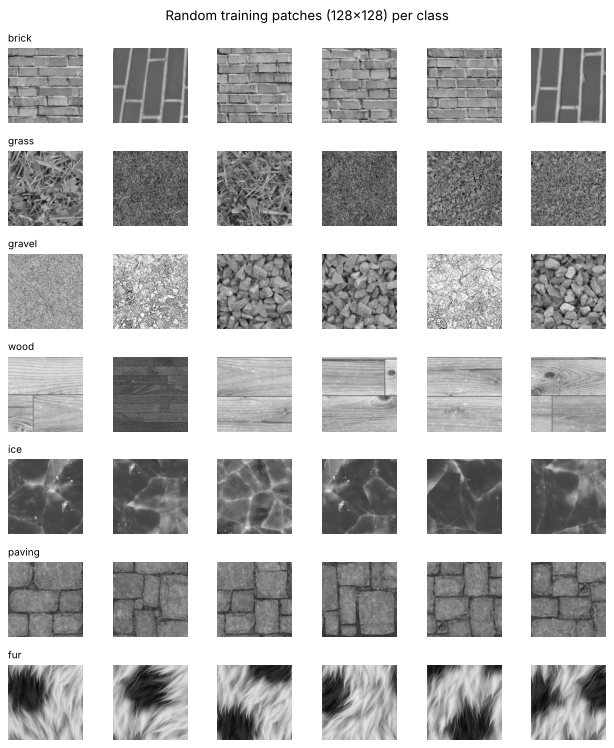

In [5]:
PATCH, STEP = 128, 64

def cut_patches(img, x0, x1, size=PATCH, with_pos=False):
    out = []
    for yy in range(0, img.shape[0] - size + 1, STEP):
        for xx in range(x0, x1 - size + 1, STEP):
            out.append((img[yy:yy + size, xx:xx + size], (xx, yy)) if with_pos else img[yy:yy + size, xx:xx + size])
    return out

train_imgs, train_y, test_imgs, test_y, test_photo, train_photo, train_pos = [], [], [], [], [], [], []
for ci, c in enumerate(class_names):
    for n, im in photos[c]:
        cut = int(im.shape[1] * 0.6)
        tr, te = cut_patches(im, 0, cut, with_pos=True), cut_patches(im, cut, im.shape[1])
        train_imgs += [p for p, _ in tr]; train_pos += [xy for _, xy in tr]
        train_y += [ci] * len(tr); train_photo += [n] * len(tr)
        test_imgs += te; test_y += [ci] * len(te); test_photo += [n] * len(te)
train_y, test_y = np.array(train_y), np.array(test_y)
print(f"training patches: {len(train_imgs)}, test patches: {len(test_imgs)}")
print("per class (train / test):", {c: (int((train_y == i).sum()), int((test_y == i).sum())) for i, c in enumerate(class_names)})

fig, axes = plt.subplots(len(class_names), 6, figsize=(8, 9.5))
for ci, c in enumerate(class_names):
    idx = np.random.default_rng(ci).choice(np.where(train_y == ci)[0], 6, replace=False)
    for a, i in zip(axes[ci], idx):
        a.imshow(train_imgs[i], cmap="gray", vmin=0, vmax=255); a.axis("off")
    axes[ci, 0].set_title(c, fontsize=9, loc="left")
plt.suptitle("Random training patches (128x128) per class"); plt.tight_layout(); plt.show()

## 5 · Step 1: SIFT descriptors (course code, adapted to patches)

Same calls as the course: `cv2.SIFT_create()` and `sift.detectAndCompute(img, None)`. `kp` is a list of keypoints (position, size, angle); `des` is an array with **one row of 128 numbers per keypoint**. `None` means "no mask: search the whole image". We keep descriptors **per patch**, because each patch needs its own histogram later.

SIFT on 514 patches took 2.9s
Collected descriptors shape: (41952, 128)
keypoints per training patch: min 8, mean 135, max 387
   brick   mean keypoints per patch: 79
   grass   mean keypoints per patch: 213
   gravel  mean keypoints per patch: 198
   wood    mean keypoints per patch: 77
   ice     mean keypoints per patch: 74
   paving  mean keypoints per patch: 166
   fur     mean keypoints per patch: 73


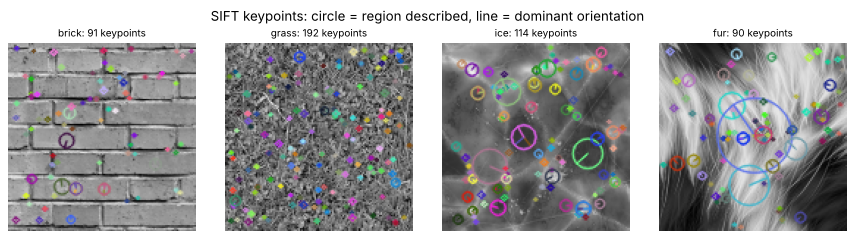

In [6]:
sift = cv2.SIFT_create()

def sift_features(img):
    kp, des = sift.detectAndCompute(img, None)
    if des is None:                                   # a completely flat patch can have no keypoints
        return [], np.zeros((0, 128), np.float32)
    return kp, des

t0 = time.perf_counter()
train_feats = [sift_features(p) for p in train_imgs]
test_feats = [sift_features(p) for p in test_imgs]
print(f"SIFT on {len(train_imgs) + len(test_imgs)} patches took {time.perf_counter() - t0:.1f}s")

descriptors = np.vstack([d for _, d in train_feats])     # ONLY training descriptors build the vocabulary
n_kp = np.array([len(d) for _, d in train_feats])
print("Collected descriptors shape:", descriptors.shape)
print(f"keypoints per training patch: min {n_kp.min()}, mean {n_kp.mean():.0f}, max {n_kp.max()}")
for ci, c in enumerate(class_names):
    print(f"   {c:7s} mean keypoints per patch: {n_kp[train_y == ci].mean():.0f}")

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for a, ci in zip(axes, [0, 1, 4, 6]):
    i = np.where(train_y == ci)[0][3]
    vis = cv2.drawKeypoints(train_imgs[i], train_feats[i][0], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    a.imshow(vis[..., ::-1]); a.set_title(f"{class_names[ci]}: {len(train_feats[i][0])} keypoints", fontsize=9); a.axis("off")
plt.suptitle("SIFT keypoints: circle = region described, line = dominant orientation"); plt.tight_layout(); plt.show()

Notice the **different number of keypoints per patch**: this is exactly why we need the histogram step. Also note smooth textures (ice) give fewer keypoints than busy ones (grass, gravel).

## 6 · Step 2: the visual vocabulary with k-means (course code)

`KMeans(n_clusters=k, random_state=42)` groups the 128-D descriptors into **k clusters**. Each cluster centre (`kmeans.cluster_centers_`, shape k×128) is one **visual word**.

How k-means works, in four lines: (1) pick k starting centres (scikit-learn uses the clever "k-means++" spread-out start), (2) assign every descriptor to its nearest centre, (3) move each centre to the mean of its assigned descriptors, (4) repeat 2–3 until nothing changes. `random_state=42` makes the random start repeatable.

The course used **k = 20**. We start there, then sweep k in section 9. To keep it quick we fit k-means on a random sample of 20,000 training descriptors (a standard shortcut; the vocabulary barely changes).

In [7]:
rng = np.random.default_rng(0)
sample = descriptors[rng.choice(len(descriptors), min(20000, len(descriptors)), replace=False)]

k = 20  # number of visual words (vocabulary size)
t0 = time.perf_counter()
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(sample)
print(f"k-means with k={k} on {len(sample)} descriptors: {time.perf_counter() - t0:.1f}s")
print("vocabulary (cluster centres) shape:", kmeans.cluster_centers_.shape)

k-means with k=20 on 20000 descriptors: 4.6s
vocabulary (cluster centres) shape: (20, 128)


## 7 · Step 3: one histogram per image (course `build_histogram`, fixed)

The course function counts words but does **not normalise**, so a patch with 300 keypoints gets a histogram 10× "taller" than one with 30 keypoints, even if the texture is the same. We divide by the total so each histogram sums to 1 (it becomes "what *fraction* of this patch's features are word w"). We also loop-free the counting with `np.bincount`.

Feature matrix shapes: (311, 20) (203, 20)


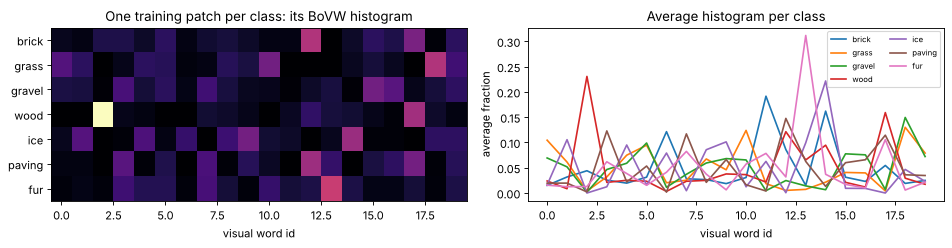

In [8]:
def build_histogram(des, kmeans=kmeans, normalise=True):
    k = kmeans.n_clusters
    hist = np.zeros(k)
    if len(des):
        words = kmeans.predict(des)                    # nearest visual word for every descriptor
        hist = np.bincount(words, minlength=k).astype(float)   # count each word (same as the course's for-loop)
        if normalise:
            hist /= hist.sum()                         # FIX: fractions, not raw counts
    return hist

X_train = np.array([build_histogram(d) for _, d in train_feats])
X_test = np.array([build_histogram(d) for _, d in test_feats])
print("Feature matrix shapes:", X_train.shape, X_test.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ex = [np.where(train_y == ci)[0][0] for ci in range(len(class_names))]
ax[0].imshow(np.array([X_train[i] for i in ex]), cmap="magma", aspect="auto")
ax[0].set_yticks(range(len(class_names)), class_names); ax[0].set_xlabel("visual word id")
ax[0].set_title("One training patch per class: its BoVW histogram")
for ci, c in enumerate(class_names):
    ax[1].plot(X_train[train_y == ci].mean(0), label=c)
ax[1].set_xlabel("visual word id"); ax[1].set_ylabel("average fraction"); ax[1].legend(fontsize=7, ncol=2)
ax[1].set_title("Average histogram per class")
plt.tight_layout(); plt.show()

Each class has its own "word frequency fingerprint". That fingerprint is what the SVM learns to recognise.

## 8 · Step 4: the texture classifier (course mini project, fixed)

The course split the 3 histograms with `train_test_split`. We already have a clean region-based split, so we train on the training patches and test on the test patches. Course model first (`SVC(kernel='linear')`), then the RBF kernel.

In [9]:
svm = SVC(kernel='linear')
svm.fit(X_train, train_y)
y_pred = svm.predict(X_test)
print("Classification Report (linear SVM, k=20):")
print(classification_report(test_y, y_pred, target_names=class_names, zero_division=0))

svm_rbf = SVC(kernel='rbf', C=10, gamma='scale').fit(X_train, train_y)
print(f"RBF SVM (C=10) accuracy with k=20: {accuracy_score(test_y, svm_rbf.predict(X_test)):.3f}")

Classification Report (linear SVM, k=20):
              precision    recall  f1-score   support

       brick       1.00      0.50      0.67        28
       grass       0.77      0.98      0.86        42
      gravel       0.65      0.74      0.69        42
        wood       0.73      1.00      0.84        35
         ice       1.00      0.93      0.96        28
      paving       0.00      0.00      0.00        14
         fur       1.00      1.00      1.00        14

    accuracy                           0.79       203
   macro avg       0.74      0.73      0.72       203
weighted avg       0.76      0.79      0.76       203

RBF SVM (C=10) accuracy with k=20: 0.936


## 9 · Experiment: vocabulary size k vs accuracy

The Key Concepts' discussion point: *changing the number of clusters (k) alters the vocabulary size and affects classification accuracy.* Let's measure it, and also check what normalising the histograms buys us.

k=  5: linear 0.764 | rbf 0.788 | rbf without normalising 0.862


k= 10: linear 0.911 | rbf 0.916 | rbf without normalising 0.946


k= 20: linear 0.921 | rbf 0.936 | rbf without normalising 0.966


k= 50: linear 0.946 | rbf 0.946 | rbf without normalising 0.980


k=100: linear 0.936 | rbf 0.975 | rbf without normalising 0.975


k=200: linear 0.936 | rbf 0.951 | rbf without normalising 0.985


k=400: linear 0.901 | rbf 0.956 | rbf without normalising 0.990
sweep took 144s


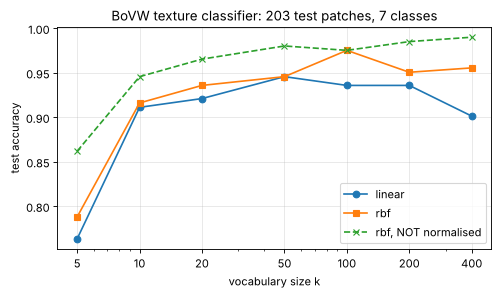

In [10]:
ks = [5, 10, 20, 50, 100, 200, 400]
res = {"linear": [], "rbf": [], "rbf, NOT normalised": []}
vocab = {}
t0 = time.perf_counter()
for kk in ks:
    km = KMeans(n_clusters=kk, random_state=42).fit(sample)
    vocab[kk] = km
    Xtr = np.array([build_histogram(d, km) for _, d in train_feats]); Xte = np.array([build_histogram(d, km) for _, d in test_feats])
    Xtr_raw = np.array([build_histogram(d, km, normalise=False) for _, d in train_feats]); Xte_raw = np.array([build_histogram(d, km, normalise=False) for _, d in test_feats])
    res["linear"].append(accuracy_score(test_y, SVC(kernel='linear', C=10).fit(Xtr, train_y).predict(Xte)))
    res["rbf"].append(accuracy_score(test_y, SVC(kernel='rbf', C=10).fit(Xtr, train_y).predict(Xte)))
    res["rbf, NOT normalised"].append(accuracy_score(test_y, SVC(kernel='rbf', C=10).fit(Xtr_raw, train_y).predict(Xte_raw)))
    print(f"k={kk:>3}: linear {res['linear'][-1]:.3f} | rbf {res['rbf'][-1]:.3f} | rbf without normalising {res['rbf, NOT normalised'][-1]:.3f}")
print(f"sweep took {time.perf_counter() - t0:.0f}s")

plt.figure(figsize=(7, 3.6))
for name, mk in zip(res, ["o-", "s-", "x--"]):
    plt.plot(ks, res[name], mk, label=name)
plt.xscale("log"); plt.xticks(ks, ks); plt.xlabel("vocabulary size k"); plt.ylabel("test accuracy")
plt.title(f"BoVW texture classifier: {len(test_imgs)} test patches, {len(class_names)} classes"); plt.grid(alpha=.3); plt.legend(); plt.show()

**Reading the curve** (numbers printed above):
- **Too few words (k = 5)**: the vocabulary is too coarse; very different patterns share a word, so classes look alike.
- **More words** helps up to a point, then levels off. With too many words each word becomes rare, histograms get sparse and noisy, and k-means and encoding get slower.
- The course's `SVC(kernel='linear')` (C = 1) only reached 79% at k = 20 (section 8; it never predicted "paving"), but with C = 10 the same linear SVM reaches 92%: `C` matters as much as `k`.
- The RBF kernel is best or joint best at every k ≥ 20.
- **Unexpected:** the un-normalised histograms scored higher. Section 9b explains why, and why you should still normalise.

We now take the best vocabulary (for normalised histograms) from the sweep and look at its mistakes.

best k = 100: accuracy 0.975
              precision    recall  f1-score   support

       brick      1.000     1.000     1.000        28
       grass      0.913     1.000     0.955        42
      gravel      1.000     0.905     0.950        42
        wood      0.972     1.000     0.986        35
         ice      1.000     0.964     0.982        28
      paving      1.000     1.000     1.000        14
         fur      1.000     1.000     1.000        14

    accuracy                          0.975       203
   macro avg      0.984     0.981     0.982       203
weighted avg      0.977     0.975     0.975       203



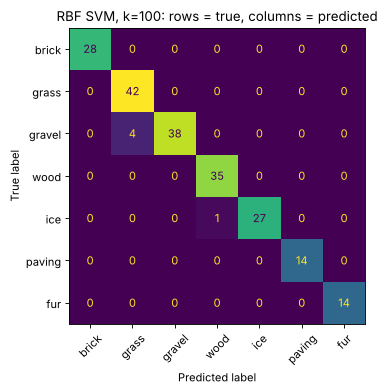

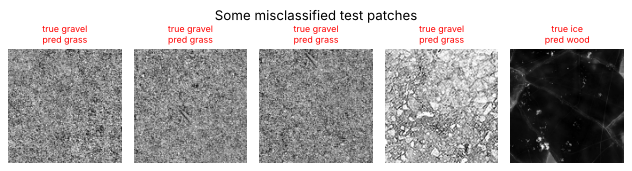

In [11]:
best_k = ks[int(np.argmax(res["rbf"]))]
km = vocab[best_k]
Xtr = np.array([build_histogram(d, km) for _, d in train_feats]); Xte = np.array([build_histogram(d, km) for _, d in test_feats])
best_svm = SVC(kernel='rbf', C=10).fit(Xtr, train_y)
pred = best_svm.predict(Xte)
print(f"best k = {best_k}: accuracy {accuracy_score(test_y, pred):.3f}")
print(classification_report(test_y, pred, target_names=class_names, digits=3))
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(test_y, pred), display_labels=class_names).plot(ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"RBF SVM, k={best_k}: rows = true, columns = predicted"); plt.tight_layout(); plt.show()

wrong = np.where(pred != test_y)[0]
if len(wrong):
    fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(1.6 * min(8, len(wrong)), 2.2))
    for a, i in zip(np.atleast_1d(axes), wrong[:8]):
        a.imshow(test_imgs[i], cmap="gray"); a.axis("off")
        a.set_title(f"true {class_names[test_y[i]]}\npred {class_names[pred[i]]}", fontsize=8, color="red")
    plt.suptitle("Some misclassified test patches"); plt.tight_layout(); plt.show()

### 9b · Normalising made things *worse* here. So why do it?

The sweep shows a surprise: on this dataset the **raw counts beat normalised histograms**. The reason is in section 5: busy textures (grass, gravel) have about 200 keypoints per patch and calm ones (wood, ice, fur) about 75. Since every patch is exactly 128×128, the **total count** is itself a useful clue, and normalising throws it away.

But that clue only works because all images are the same size. Real images are not. Test: keep the models trained on 128×128 patches, but classify **bigger 192×192 patches** cut from the same test regions (same textures, same scale, just more area, so more keypoints).

In [12]:
km = vocab[100]
big_test, big_y = [], []
for ci, c in enumerate(class_names):
    for n, im in photos[c]:
        cut = int(im.shape[1] * 0.6)
        b = cut_patches(im, cut, im.shape[1], size=192)
        big_test += b; big_y += [ci] * len(b)
big_y = np.array(big_y)
big_des = [sift_features(p)[1] for p in big_test]
for norm in [True, False]:
    Xtr = np.array([build_histogram(d, km, normalise=norm) for _, d in train_feats])
    Xbig = np.array([build_histogram(d, km, normalise=norm) for d in big_des])
    Xte = np.array([build_histogram(d, km, normalise=norm) for _, d in test_feats])
    m = SVC(kernel='rbf', C=10).fit(Xtr, train_y)
    print(f"normalise={norm!s:5}: 128x128 test patches {accuracy_score(test_y, m.predict(Xte)):.3f} | "
          f"192x192 test patches ({len(big_test)}) {accuracy_score(big_y, m.predict(Xbig)):.3f}")

normalise=True : 128x128 test patches 0.975 | 192x192 test patches (96) 0.958


normalise=False: 128x128 test patches 0.975 | 192x192 test patches (96) 0.615


With raw counts, the bigger patches "look busier" than anything seen in training, and accuracy collapses; normalised histograms do not care about image size. **Lesson:** normalise whenever images (or numbers of keypoints) vary in size, which in practice is almost always. Our equal-size patches were a special case.

## 10 · What does a "visual word" look like?

A visual word is just a point in 128-D space, which we cannot look at directly. But we can look at the **image regions whose descriptors are closest to that word's centre**. Below, for the k=50 vocabulary, we show, for 5 words, the 8 training regions nearest the centre (each region cut out around its keypoint, at the keypoint's scale and rotated to its orientation). We pick, for each of 5 classes, the word that is most typical of that class.

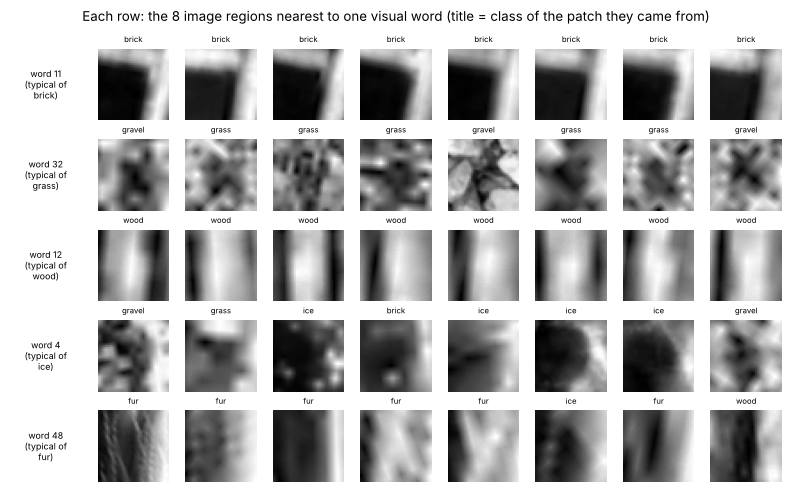

In [13]:
km50 = vocab[50]
all_kp = [(i, kp) for i, (kps, _) in enumerate(train_feats) for kp in kps]   # keypoints in the same order as `descriptors`
dist = km50.transform(descriptors)                     # distance of every training descriptor to every word centre
H50 = np.array([build_histogram(d, km50) for _, d in train_feats])
class_mean = np.array([H50[train_y == ci].mean(0) for ci in range(len(class_names))])

def region(patch_idx, kp, out=40):
    """Cut the region a SIFT keypoint describes, rotated upright, resized to out x out."""
    big = cv2.copyMakeBorder(train_imgs[patch_idx], 64, 64, 64, 64, cv2.BORDER_REFLECT)
    x, y = kp.pt[0] + 64, kp.pt[1] + 64
    M = cv2.getRotationMatrix2D((x, y), kp.angle, out / (3 * kp.size))   # scale so 3 x keypoint size fills the tile
    M[:, 2] += (out / 2 - x, out / 2 - y)
    return cv2.warpAffine(big, M, (out, out))

show_classes = ["brick", "grass", "wood", "ice", "fur"]
fig, axes = plt.subplots(len(show_classes), 9, figsize=(10, 6.2))
for r, c in enumerate(show_classes):
    ci = class_names.index(c)
    others = np.delete(class_mean, ci, axis=0).max(0)
    w = int(np.argmax(class_mean[ci] - others))        # the word most over-represented in this class
    nearest, seen = [], []
    for j in np.argsort(dist[:, w]):               # skip duplicates: overlapping patches contain the same keypoint twice
        pi, kp = all_kp[j]
        gx, gy = train_pos[pi][0] + kp.pt[0], train_pos[pi][1] + kp.pt[1]
        if any(ph == train_photo[pi] and abs(gx - x0) < 4 and abs(gy - y0) < 4 for ph, x0, y0 in seen):
            continue
        seen.append((train_photo[pi], gx, gy)); nearest.append(j)
        if len(nearest) == 8:
            break
    axes[r, 0].text(0.5, 0.5, f"word {w}\n(typical of\n{c})", ha="center", va="center", fontsize=8); axes[r, 0].axis("off")
    for a, j in zip(axes[r, 1:], nearest):
        pi, kp = all_kp[j]
        a.imshow(region(pi, kp), cmap="gray"); a.axis("off")
        a.set_title(class_names[train_y[pi]], fontsize=7)
plt.suptitle("Each row: the 8 image regions nearest to one visual word (title = class of the patch they came from)"); plt.tight_layout(); plt.show()

(The brick row looks almost identical because that brick photo is a *tileable* texture: the same brick corner repeats across the image.) Each row really is "one kind of small pattern": the same local structure (an edge, a blob, a line ending…) at different places and scales. Words are **shared** across classes (the region titles show which class each came from), and that is the point: it is the **mix** of word frequencies, not any single word, that identifies a texture.

## 11 · A harder, more honest test: a photo the model has never seen

Section 8 tested on unseen *regions* of the same photos. A real material recogniser must handle a **new photo** (different lighting, scale, camera). For the five classes that have 2 or 3 photos we hold out **one whole photo per class**, train on everything else (including the 1-photo classes), and test only on the held-out photos.

In [14]:
holdout = {"brick": "brick_B", "grass": "grass_C", "gravel": "gravel_A", "wood": "wood_A", "ice": "ice_B"}
all_imgs = train_imgs + test_imgs
all_feats = train_feats + test_feats
all_y = np.concatenate([train_y, test_y])
all_photo = np.array(train_photo + test_photo)
is_test = np.isin(all_photo, list(holdout.values()))
print("held-out photos:", list(holdout.values()), f"-> {is_test.sum()} test patches, {(~is_test).sum()} training patches")

desc_tr = np.vstack([all_feats[i][1] for i in np.where(~is_test)[0]])
km_h = KMeans(n_clusters=best_k, random_state=42).fit(desc_tr[rng.choice(len(desc_tr), min(20000, len(desc_tr)), replace=False)])
Xa = np.array([build_histogram(d, km_h) for _, d in all_feats])
clf = SVC(kernel='rbf', C=10).fit(Xa[~is_test], all_y[~is_test])
pred_h = clf.predict(Xa[is_test])
print(f"accuracy on never-seen photos: {accuracy_score(all_y[is_test], pred_h):.3f}")
for c, n in holdout.items():
    m = all_photo[is_test] == n
    counts = np.bincount(pred_h[m], minlength=len(class_names))
    top = ", ".join(f"{class_names[j]} {counts[j]}" for j in np.argsort(counts)[::-1] if counts[j])
    print(f"   {n:8s} (true {c:6s}): {(pred_h[m] == class_names.index(c)).mean():.2f} correct | predicted as: {top}")

held-out photos: ['brick_B', 'grass_C', 'gravel_A', 'wood_A', 'ice_B'] -> 231 test patches, 283 training patches


accuracy on never-seen photos: 0.333
   brick_B  (true brick ): 0.00 correct | predicted as: gravel 35
   grass_C  (true grass ): 0.94 correct | predicted as: grass 33, gravel 2
   gravel_A (true gravel): 0.57 correct | predicted as: gravel 20, paving 14, brick 1
   wood_A   (true wood  ): 0.00 correct | predicted as: brick 75, gravel 10, fur 6
   ice_B    (true ice   ): 0.69 correct | predicted as: ice 24, gravel 10, fur 1


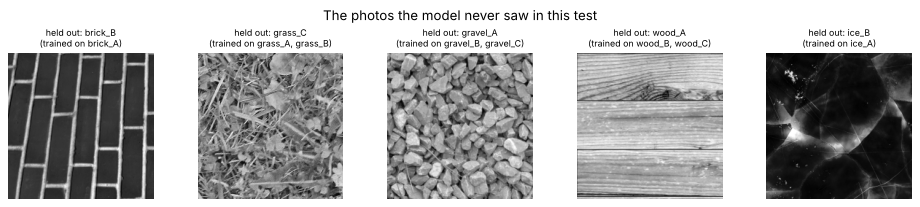

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for a, (c, n) in zip(axes, holdout.items()):
    other = [p for p, _ in photos[c] if p != n]
    a.imshow(dict(photos[c])[n][:200, :200], cmap="gray"); a.axis("off")
    a.set_title(f"held out: {n}\n(trained on {', '.join(other)})", fontsize=8)
plt.suptitle("The photos the model never saw in this test"); plt.tight_layout(); plt.show()

This is the honest picture: only **33%** of patches from never-seen photos are classified correctly. Grass (94%) and ice (69%) transfer well because their photos look alike. The light pine planks (`wood_A`) are called **brick** (horizontal boards with joints really do look like a brick wall when you only count local patterns), and scikit-image's brick wall (`brick_B`: long, slanted dark bricks with bright mortar) is called gravel: it looks nothing like the brick photo it was trained on (short horizontal bricks). When the same material is photographed **at a very different scale or style**, the word frequencies change and BoVW fails. Classic fixes: more and more varied training photos per class, dense SIFT at several scales, colour descriptors, or a CNN that learns features from thousands of images.

## 12 · Extra experiment: detected keypoints vs a dense grid

`detectAndCompute` only describes "interesting" points, and smooth textures get few of them. A common BoVW improvement is **dense SIFT**: put keypoints on a regular grid (here every 8 pixels, size 16) and only *compute* descriptors there with `sift.compute`. Same vocabulary size, same SVM, same region split as section 8.

In [16]:
grid_kp = [cv2.KeyPoint(float(x), float(y), 16) for y in range(8, PATCH - 7, 8) for x in range(8, PATCH - 7, 8)]
t0 = time.perf_counter()
dense_tr = [sift.compute(p, grid_kp)[1] for p in train_imgs]
dense_te = [sift.compute(p, grid_kp)[1] for p in test_imgs]
dd = np.vstack(dense_tr)
km_d = KMeans(n_clusters=best_k, random_state=42).fit(dd[rng.choice(len(dd), 20000, replace=False)])
Xd_tr = np.array([build_histogram(d, km_d) for d in dense_tr]); Xd_te = np.array([build_histogram(d, km_d) for d in dense_te])
acc_dense = accuracy_score(test_y, SVC(kernel='rbf', C=10).fit(Xd_tr, train_y).predict(Xd_te))
print(f"dense grid: {len(grid_kp)} descriptors per patch, accuracy {acc_dense:.3f}  ({time.perf_counter() - t0:.0f}s)")
print(f"detected keypoints (section 9, same k={best_k}): accuracy {max(res['rbf']):.3f}")

dense grid: 225 descriptors per patch, accuracy 0.729  (22s)
detected keypoints (section 9, same k=100): accuracy 0.975


**Result: dense SIFT was clearly worse here** (about 73% vs 97.5%), the opposite of what many papers report. Two likely reasons, both visible in this notebook: (1) a single fixed scale (size 16) and no rotation normalisation (grid keypoints have no orientation), while detected keypoints adapt to each pattern's scale and angle; (2) with a fixed 225 descriptors per patch, the "number of keypoints" clue from section 9b disappears. Dense SIFT usually shines with several scales and much larger datasets. The lesson: **measure, don't assume.**

## 13 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem | Fix |
|---|---|---|---|
| 1 | 3 images (`sample.jpg`, `left.jpg`, `right.jpg`), one per class | **Fundamentally broken**: with one image per class, a train/test split leaves the test class unseen in training, so accuracy is 0% by construction (course output: accuracy 0.00, support 1). `left.jpg`/`right.jpg` are OpenCV's stereo-camera samples, not textures, and none of the files are provided. | Built a 7-class dataset from 15 real texture photos, many patches per class, region-based train/test split plus an "unseen photo" test. |
| 2 | `train_test_split` on 3 histograms, `test_size=0.3` | 2 training samples, 1 test sample; the report and accuracy are meaningless. | Clean split with every class on both sides (hundreds of patches). |
| 3 | `build_histogram` returns raw counts | Histograms depend on how many keypoints an image happens to have. | Normalised to sum to 1 (L1); measured the effect. |
| 4 | k-means fitted on descriptors of *all* images | With a real split, the vocabulary must be learned from **training images only**, or test information leaks in. | Fitted k-means on training descriptors only. |
| 5 | `y.extend([idx]*len(des))` in the first cell | Builds a per-descriptor label list that is never used (dead code). | Removed. |
| 6 | Fixed k = 20, no evaluation beyond one report | The Key Concepts ask to explore k. | k sweep 5 → 400, confusion matrix, visual-word visualisation, dense SIFT comparison. |
| 7 | `RuntimeWarning ... matmul` in k-means | Comes from the course author's numpy/macOS maths library, not from BoVW. | Not reproducible here; nothing to fix in the method. |
| 8 | Images read from disk with `cv2.imread(path)` and no check | `cv2.imread` returns `None` for a missing file and SIFT then crashes with a cryptic error. | Images are downloaded and cached by a helper with a clear error message. |

## 14 · Results, honestly

All numbers come from the run above.
- The course pipeline (3 images, one per class) scores **0%** by construction, reproduced in section 3.
- With a real dataset (7 classes, 15 photos, 311 training and 203 test patches from separate regions) the same SIFT → k-means → histogram → SVM pipeline reaches **79%** with the course's exact settings (k = 20, `SVC(kernel='linear')`, C = 1), **93.6%** with k = 20 and an RBF SVM, and **97.5%** with the best vocabulary (k = 100) and an RBF SVM.
- Vocabulary size matters: k = 5 gave 79% (RBF), k = 100 gave 97.5%, and larger vocabularies did not help further (95–96% at k = 200–400).
- Raw counts beat normalised histograms on equal-size patches (e.g. 99.0% vs 95.6% at k = 400), because the keypoint count itself separates busy from calm textures. On bigger 192×192 test patches the raw-count model fell to **61.5%**, while the normalised one kept **95.8%**: normalisation is what makes BoVW robust to image size.
- On whole **photos the model has never seen**, accuracy falls to **33%**. This is the most realistic number in this notebook: 2–3 photos per class are not enough variety for BoVW to generalise to a new photo of the same material in a different style or scale.
- Dense single-scale SIFT scored 72.9% vs 97.5% for detected keypoints on this data.
- Caveats: the texture photos come from 3D-graphics asset libraries (some are tiled/edited), the dataset is small, and texture scale was only roughly matched.

## 15 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `AttributeError: module 'cv2' has no attribute 'SIFT_create'` | Very old OpenCV (< 4.4) | `pip install --upgrade opencv-python` (or use `cv2.xfeatures2d.SIFT_create()` with old contrib builds) |
| `cv2.error ... (-215:Assertion failed) !_src.empty()` | `cv2.imread` returned `None` (wrong path) | Check the file exists; print `img is None` |
| `TypeError` / crash in `kmeans.predict(des)` | `des` is `None` for an image with no keypoints | Check `if des is not None` (or return an all-zero histogram, as here) |
| Accuracy 0% or a report with `support 1.0` | One image per class, test class unseen in training (the course bug) | Many images per class; stratified split |
| `UndefinedMetricWarning: Precision is ill-defined` | Some class never predicted (or absent from the test set) | Usually a sign the dataset/split is broken; fix the data |
| Very high accuracy that does not hold on new photos | Train and test patches overlap or come from the same photo | Split by region or by photo, never shuffle overlapping patches |
| k-means very slow | Millions of descriptors, large k | Fit on a random sample (here 20,000) or use `MiniBatchKMeans` |

## 16 · Try this yourself

1. Change `PATCH` to 64 or 192. More, smaller patches or fewer, bigger ones: which gives better accuracy, and why (keypoints per patch)?
2. Replace SIFT with ORB (`cv2.ORB_create()`); ORB descriptors are binary (32 bytes), so convert them with `des.astype(np.float32)` before k-means. Compare accuracy and speed.
3. Swap the SVM for `KNeighborsClassifier(n_neighbors=5)` on the histograms. Which classifier works better here?
4. Add another texture class: find a texture photo (e.g. another file from the three.js `examples/textures` folder), add it to `sources`, rerun.
5. Change the hold-out photos in section 11 (e.g. hold out `grass_A` instead of `grass_C`). Does the accuracy change a lot? What does that tell you?
6. Try `MiniBatchKMeans` from `sklearn.cluster` with k = 1000: faster? better?

## 17 · Viva questions (with short model answers)

1. **What is Bag of Visual Words?** Representing an image as a histogram of how often each "visual word" (a cluster of similar local descriptors) occurs, then classifying that histogram, like counting words in a document.
2. **Give the four steps of the pipeline.** Extract local descriptors (SIFT) → cluster training descriptors with k-means to make a vocabulary → assign each descriptor to its nearest word and count (histogram) → train a classifier (SVM) on the histograms.
3. **Why do we need the histogram step at all?** Images produce different numbers of descriptors; the histogram converts them into one fixed-length vector of k numbers that a classifier can use.
4. **What is a visual word?** A k-means cluster centre in descriptor space (a 128-D vector for SIFT): a typical local pattern.
5. **What does k control, and how do you choose it?** The vocabulary size. Too small: different patterns merge, low accuracy. Too large: sparse, noisy histograms and slower. Choose by validation (here we swept 5 to 400).
6. **Why normalise the histograms?** So that the representation does not depend on how many keypoints an image has (texture-rich vs smooth, large vs small).
7. **Why must the vocabulary be built from training images only?** Otherwise information from the test images leaks into the features and the test score is optimistic.
8. **Why did the course notebook get 0%?** One image per class; after the split the test image's class was never in training, so the SVM could not output it.
9. **What does a SIFT descriptor contain?** 128 numbers: histograms of gradient orientations (8 bins) in a 4×4 grid of cells around the keypoint, normalised; rotation is handled by measuring angles relative to the keypoint's dominant orientation.
10. **What information does BoVW lose?** Spatial layout: where the features are. (Spatial pyramid matching adds coarse layout back.)
11. **How does k-means work?** Choose k centres, assign each point to the nearest centre, move each centre to the mean of its points, repeat until stable.
12. **Is k-means supervised?** No, it never sees labels. Only the SVM at the end uses labels.
13. **Why is BoVW suited to textures?** A texture is a repeated statistical pattern; the frequency of local patterns describes it well, and position does not matter.
14. **Why might accuracy drop on a new photo of the same material?** Different scale, lighting and style shift the word frequencies; with few training photos the classifier has not seen that variety.
15. **What replaced BoVW in modern vision?** CNNs, which learn the features (and the "vocabulary") from data end to end instead of using hand-designed SIFT + k-means.